Total Cohort: 2126 patients, 21 clinical biomarkers
Target Class Distribution:
 fetal_health
0    0.778457
1    0.138758
2    0.082785
Name: proportion, dtype: float64

     OUT-OF-FOLD MULTI-CLASS CLINICAL EVALUATION
              precision    recall  f1-score   support

      Normal     0.9782    0.9480    0.9629      1655
     Suspect     0.7765    0.8949    0.8315       295
Pathological     0.9011    0.9318    0.9162       176

    accuracy                         0.9393      2126
   macro avg     0.8852    0.9249    0.9035      2126
weighted avg     0.9438    0.9393    0.9408      2126

Macro One-vs-Rest ROC-AUC: 0.9854


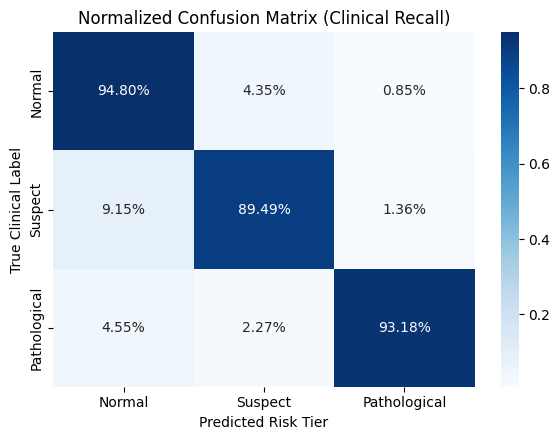


--> Generating SHAP attribution plots for Pathological Risk (Class 2)...


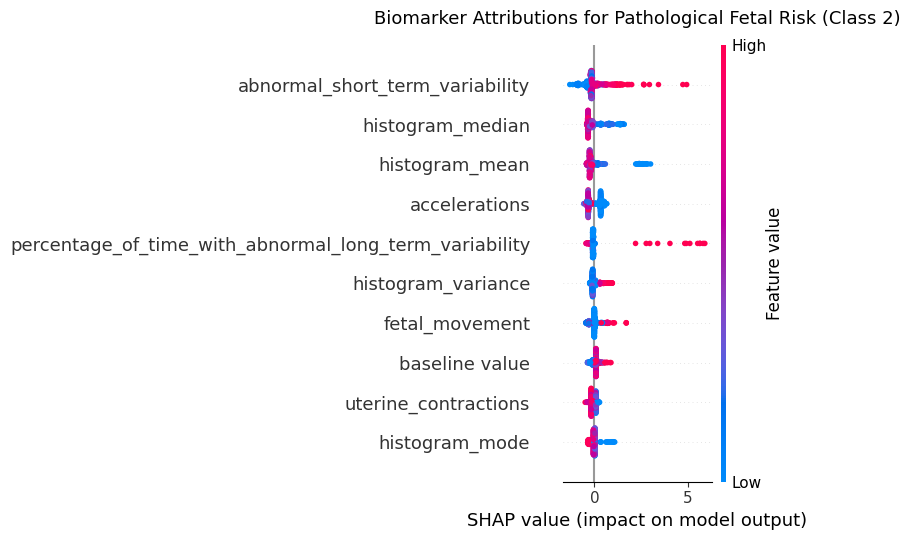

Saved SHAP plot to: /kaggle/working/shap_fetal_pathological_risk.png


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import lightgbm as lgb
import shap

# ==========================================
# 1. LOAD & PREPARE DATASET
# ==========================================
# Ensure the 'fetal-health-classification' dataset is added to the Kaggle notebook
df = pd.read_csv('/kaggle/input/datasets/andrewmvd/fetal-health-classification/fetal_health.csv')

# Feature matrix and 0-indexed target: 0=Normal, 1=Suspect, 2=Pathological
X = df.drop(columns=['fetal_health'])
y = (df['fetal_health'] - 1).astype(int)

class_names = ['Normal', 'Suspect', 'Pathological']
print(f"Total Cohort: {X.shape[0]} patients, {X.shape[1]} clinical biomarkers")
print("Target Class Distribution:\n", y.value_counts(normalize=True))

# ==========================================
# 2. STRATIFIED CROSS-VALIDATION PIPELINE
# ==========================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(df))
oof_probs = np.zeros((len(df), 3))

# Balanced class weights to heavily penalize missing pathological cases
classes = np.unique(y)
class_weights = {c: len(y) / (len(classes) * np.sum(y == c)) for c in classes}

# Track the last fold validation data for explainability
last_X_val_scaled = None
last_X_val_df = None
last_model = None

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    # Scale while retaining DataFrame column names (prevents UserWarning)
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train), 
        columns=X.columns, 
        index=X_train.index
    )
    X_val_scaled = pd.DataFrame(
        scaler.transform(X_val), 
        columns=X.columns, 
        index=X_val.index
    )
    
    model = lgb.LGBMClassifier(
        n_estimators=180,
        learning_rate=0.04,
        max_depth=4,
        class_weight=class_weights,
        random_state=42,
        verbosity=-1
    )
    
    model.fit(X_train_scaled, y_train)
    probs = model.predict_proba(X_val_scaled)
    
    oof_probs[val_idx] = probs
    oof_preds[val_idx] = np.argmax(probs, axis=1)
    
    # Cache the final fold for SHAP explanation
    last_X_val_scaled = X_val_scaled
    last_X_val_df = X_val
    last_model = model

# ==========================================
# 3. CLINICAL EVALUATION REPORT
# ==========================================
print("\n" + "=" * 60)
print("     OUT-OF-FOLD MULTI-CLASS CLINICAL EVALUATION")
print("=" * 60)
print(classification_report(y, oof_preds, target_names=class_names, digits=4))
print(f"Macro One-vs-Rest ROC-AUC: {roc_auc_score(y, oof_probs, multi_class='ovr'):.4f}")

# Optional: Normalized confusion matrix to inspect recall directly
cm = confusion_matrix(y, oof_preds, normalize='true')
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='.2%', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Normalized Confusion Matrix (Clinical Recall)", fontsize=12)
plt.xlabel("Predicted Risk Tier")
plt.ylabel("True Clinical Label")
plt.tight_layout()
plt.show()

# ==========================================
# 4. SHAP CLINICAL EXPLAINABILITY (ROBUST)
# ==========================================
print("\n--> Generating SHAP attribution plots for Pathological Risk (Class 2)...")
explainer = shap.TreeExplainer(last_model)
shap_vals = explainer.shap_values(last_X_val_scaled)

# Handle both older SHAP (list of 2D arrays) and modern SHAP (single 3D array)
if isinstance(shap_vals, list):
    class_2_shap = shap_vals[2]
elif len(shap_vals.shape) == 3:
    # Shape is (n_samples, n_features, n_classes) -> extract Class 2
    class_2_shap = shap_vals[:, :, 2]
else:
    class_2_shap = shap_vals

plt.figure(figsize=(10, 6))
shap.summary_plot(
    class_2_shap,
    last_X_val_df,
    max_display=10,
    show=False
)
plt.title("Biomarker Attributions for Pathological Fetal Risk (Class 2)", fontsize=13, pad=15)
plt.tight_layout()

output_path = "/kaggle/working/shap_fetal_pathological_risk.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved SHAP plot to: {output_path}")